<a href="https://colab.research.google.com/github/hanviol/ev-spare-parts-import-prioritization/blob/main/Azarya_Melkamu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EV Spare-Parts Import Prioritization

Which EV replacement parts should a new importer in Ethiopia stock first?

Raw data: release [`raw-vehicles-2026-11-18`](https://github.com/hanviol/ev-spare-parts-import-prioritization/releases/tag/raw-vehicles-2026-11-18),
collected from Adey Market, Jiji, AfroMekina, Mekina and Gezat with the scrapers in [`collect/`](https://github.com/hanviol/ev-spare-parts-import-prioritization/tree/main/collect).

> Listing counts show marketplace visibility, not sales.

## 1. Setup

In [1]:
import hashlib
import io
import os
import re

import matplotlib.pyplot as plt
import pandas as pd
import requests

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

REPO = "hanviol/ev-spare-parts-import-prioritization"
RAW_TAG = "raw-vehicles-2026-11-18"
RELEASE_URL = f"https://github.com/{REPO}/releases/download/{RAW_TAG}/"

OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 2. Load raw data

Files are downloaded from the release and checked against `checksums.txt`.

In [2]:
def download(name):
    response = requests.get(RELEASE_URL + name, timeout=300)
    response.raise_for_status()
    return response.content


expected = {}
for line in download("checksums.txt").decode("utf-8").strip().splitlines():
    digest, name = line.split("  ")
    expected[name] = digest

raw = {}
for name in ["listings_adey.csv", "listings_jiji.csv", "listings_afromekina.csv", "listings_mekina.csv", "listings_gezat.csv"]:
    content = download(name)
    if hashlib.sha256(content).hexdigest() != expected[name]:
        raise ValueError(f"{name} does not match its checksum")
    raw[name] = pd.read_csv(io.BytesIO(content))
    print(f"{name:<26} {len(raw[name]):>6} rows   checksum OK")

adey = raw["listings_adey.csv"]
jiji = raw["listings_jiji.csv"]
afro = raw["listings_afromekina.csv"]
mekina = raw["listings_mekina.csv"]
gezat = raw["listings_gezat.csv"]

listings_adey.csv            8366 rows   checksum OK


listings_jiji.csv            3787 rows   checksum OK


listings_afromekina.csv       425 rows   checksum OK


listings_mekina.csv            58 rows   checksum OK


listings_gezat.csv             26 rows   checksum OK


## 3. Cleaning

All sources become one table: `source, listing_id, title, model, price_etb, year, mileage_km, seller`.

### 3.1 Model names

Titles are matched against patterns, specific names first (`yuan up` before `yuan`).
Titles with DM-i, DM-p, PHEV, plug-in or hybrid are plug-in hybrids.

In [3]:
MODEL_PATTERNS = [
    ("BYD Seagull", r"sea ?gull|segull|seagul|dolphin mini|atto ?1\b"),
    ("BYD Yuan Up", r"yuan ?up|atto ?2\b"),
    ("BYD Yuan Plus", r"yuan ?plus|yuan ?pluse|yuan ?blus|atto ?3\b"),
    ("BYD e2", r"\be2\b"),
    ("BYD Dolphin", r"dolphin"),
    ("BYD Sealion", r"sea ?lion"),
    ("BYD Seal", r"\bseal\b"),
    ("BYD Song Plus", r"song ?plus|song ?pluse"),
    ("BYD Song L", r"song ?l\b"),
    ("BYD Tang", r"\btang\b"),
    ("BYD Qin Plus", r"\bqin\b"),
    ("BYD Leopard 3", r"(leopard|lepard) ?0?3\b"),
    ("BYD Leopard 5/7/8", r"(leopard|lepard) ?0?[578]\b|titanium"),
    ("Toyota bZ4X", r"bz ?4 ?x"),
    ("Toyota bZ3X", r"bz ?3 ?x"),
    ("Toyota bZ3", r"bz ?3\b"),
    ("Toyota bZ5", r"bz ?5\b"),
    ("VW ID.4", r"\bid ?4\b"),
    ("VW ID.6", r"\bid ?6\b"),
    ("VW ID.3", r"\bid ?3\b"),
    ("VW ID. UNYX", r"unyx"),
    ("Changan Benben E-Star", r"e ?star|ben ?ben"),
    ("Changan Q05", r"\bq ?05\b|nevo"),
    ("Changan Deepal", r"deepal"),
    ("Dongfeng Nammi", r"nammi|nami ?01"),
    ("GAC Aion Y", r"aion"),
    ("Leapmotor T03", r"leap ?motor|\bt ?03\b"),
    ("Neta U", r"neta ?u\b"),
    ("Neta Aya", r"neta ?aya|\baya\b"),
    ("BMW iX3", r"\bix ?3\b"),
    ("Tesla Model Y", r"tesla|model ?y\b"),
]

ALWAYS_HYBRID = ["BYD Leopard 5/7/8"]
HYBRID_WORDS = r"dm ?i\b|\bdmi\b|dm ?p\b|phev|plug ?in|hybrid"


def simplify(text):
    text = str(text).lower()
    text = re.sub(r"[_\-./()|,]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def find_model(text):
    text = simplify(text)
    for model, pattern in MODEL_PATTERNS:
        if re.search(pattern, text):
            return model
    return None


def is_hybrid(text):
    return bool(re.search(HYBRID_WORDS, simplify(text)))

### 3.2 Prices and years

Prices outside 1–30 million ETB are set to missing (typos and deposits, about 1%).
Years must be between 2015 and 2026.

In [4]:
MIN_PRICE = 1_000_000
MAX_PRICE = 30_000_000


def to_number(value):
    if pd.isna(value):
        return None
    digits = re.sub(r"[^0-9.]", "", str(value))
    if digits in ("", "."):
        return None
    return float(digits)


def clean_price(value):
    price = to_number(value)
    if price is None or price < MIN_PRICE or price > MAX_PRICE:
        return None
    return price


def find_year(value):
    match = re.search(r"\b(20[12][0-9])\b", str(value))
    if match is None:
        return None
    year = int(match.group(1))
    if 2015 <= year <= 2026:
        return year
    return None

### 3.3 Combine the sources

* **Adey:** model from the title, otherwise from the Adey page. The title wins because Adey's pages are not always right (its "ID.4 Crozz" page is mostly ID.6).
* **Jiji:** the same advert appears under several searches, so repeated IDs are dropped.

In [5]:
ADEY_PAGE_MODEL = {
    "BYD Seagull": "BYD Seagull",
    "BYD Yuan Up": "BYD Yuan Up",
    "BYD Yuan Plus": "BYD Yuan Plus",
    "BYD Sealion": "BYD Sealion",
    "BYD Song Plus": "BYD Song Plus",
    "BYD Tang": "BYD Tang",
    "BYD Qin Plus": "BYD Qin Plus",
    "BYD Seal": "BYD Seal",
    "Changan Benben E-Star": "Changan Benben E-Star",
    "Changan Deepal": "Changan Deepal",
    "VW ID.4": "VW ID.4",
    "VW ID.6": "VW ID.6",
    "Dongfeng Nammi": "Dongfeng Nammi",
    "GAC Aion Y": "GAC Aion Y",
    "Leapmotor T03": "Leapmotor T03",
    "Neta U": "Neta U",
    "Neta Aya": "Neta Aya",
    "BMW iX3": "BMW iX3",
    "Tesla Model Y": "Tesla Model Y",
    # pages that mix models
    "Toyota bZ series": "Toyota bZ (unspecified)",
    "VW ID.4 Crozz": "VW ID (unspecified)",
    "BYD Leopard": "BYD Leopard (unspecified)",
    "BYD Yuan": "BYD (unspecified)",
    "BYD Song": "BYD Song (unspecified)",
}


def adey_model(row):
    model = find_model(row["title"])
    if model is None:
        model = ADEY_PAGE_MODEL.get(row["model_label"])
    return model


adey_clean = pd.DataFrame({
    "source": "Adey",
    "listing_id": adey["listing_id"].astype(str),
    "title": adey["title"],
    "model": adey.apply(adey_model, axis=1),
    "price_etb": adey["price_text"].apply(clean_price),
    "year": adey["title"].apply(find_year),
    "mileage_km": None,
    "seller": adey["seller"],
})

jiji_unique = jiji.drop_duplicates("listing_id")
jiji_clean = pd.DataFrame({
    "source": "Jiji",
    "listing_id": jiji_unique["listing_id"].astype(str),
    "title": jiji_unique["title"],
    "model": jiji_unique["title"].apply(find_model),
    "price_etb": jiji_unique["price_value"].apply(clean_price),
    "year": jiji_unique["title"].apply(find_year),
    "mileage_km": jiji_unique["mileage_km"],
    "seller": jiji_unique["seller_account_id"].astype(str),
})

afro_text = afro["make"].fillna("") + " " + afro["model"].fillna("") + " " + afro["title"].fillna("")
afro_clean = pd.DataFrame({
    "source": "AfroMekina",
    "listing_id": afro["listing_id"].astype(str),
    "title": afro_text,
    "model": afro_text.apply(find_model),
    "price_etb": afro["price_value"].apply(clean_price),
    "year": afro["year"].apply(find_year),
    "mileage_km": afro["mileage_km"],
    "seller": afro["seller_account_id"].astype(str),
})

mekina_text = mekina["make"].fillna("") + " " + mekina["model"].fillna("") + " " + mekina["title"].fillna("")
mekina_clean = pd.DataFrame({
    "source": "Mekina",
    "listing_id": mekina["listing_id"].astype(str),
    "title": mekina_text,
    "model": mekina_text.apply(find_model),
    "price_etb": mekina["price_value"].apply(clean_price),
    "year": mekina["year"].apply(find_year),
    "mileage_km": mekina["mileage_km"],
    "seller": None,
})

gezat_text = gezat["make"].fillna("") + " " + gezat["model"].fillna("") + " " + gezat["year"].astype(str) + " " + gezat["mileage_text"].fillna("")
gezat_clean = pd.DataFrame({
    "source": "Gezat",
    "listing_id": gezat["listing_id"].astype(str),
    "title": gezat_text,
    "model": gezat_text.apply(find_model),
    "price_etb": gezat["price_text"].apply(clean_price),
    "year": gezat["year"].apply(find_year),
    "mileage_km": gezat["mileage_text"].apply(to_number),
    "seller": None,
})

listings = pd.concat([adey_clean, jiji_clean, afro_clean, mekina_clean, gezat_clean], ignore_index=True)
listings["model"] = listings["model"].fillna("Other EV")
for column in ["price_etb", "year", "mileage_km"]:
    listings[column] = pd.to_numeric(listings[column], errors="coerce")

listings.groupby("source").size().rename("rows")

source
Adey          8366
AfroMekina     425
Gezat           26
Jiji          3149
Mekina          58
Name: rows, dtype: int64

### 3.4 Remove plug-in hybrids

In [6]:
listings["hybrid"] = listings["title"].apply(is_hybrid) | listings["model"].isin(ALWAYS_HYBRID)
print("Plug-in hybrids removed:", listings["hybrid"].sum())
listings = listings[~listings["hybrid"]].drop(columns="hybrid").copy()

Plug-in hybrids removed: 1113


### 3.5 Remove duplicates

* **Adey, Gezat:** same model, price and title on the same source = repost of the same car.
* **Jiji, AfroMekina, Mekina:** each advert has its own ID, so nothing more is removed.
* **Across sources:** not merged; section 4 uses each model's share *within* each source instead.

In [7]:
listings["title_key"] = listings["title"].apply(simplify)
same_car = listings.duplicated(subset=["source", "model", "price_etb", "title_key"], keep="first")
is_duplicate = same_car & listings["price_etb"].notna() & listings["source"].isin(["Adey", "Gezat"])

before = listings.groupby("source").size()
listings = listings[~is_duplicate].drop(columns="title_key").copy()
after = listings.groupby("source").size()

pd.DataFrame({"before": before, "removed": before - after, "after": after})

,before,removed,after
source,,,
Adey,7443,1917,5526
AfroMekina,425,0,425
Gezat,26,16,10
Jiji,2960,0,2960
Mekina,57,0,57


### 3.6 Missing values

Missing values are kept as missing: price "on request", no year in the title, no mileage on Adey, no seller ID on Mekina/Gezat.

In [8]:
missing = listings[["price_etb", "year", "mileage_km", "seller"]].isna().groupby(listings["source"]).mean()
print((missing * 100).round(0).astype(int).astype(str) + " %")

listings.to_csv(f"{OUTPUT_DIR}/cleaned_vehicle_listings.csv", index=False)
print("\nSaved", len(listings), "cleaned listings")

           price_etb  year mileage_km seller
source                                      
Adey            43 %  62 %      100 %    0 %
AfroMekina       0 %   0 %       13 %    0 %
Gezat            0 %   0 %        0 %  100 %
Jiji             1 %   1 %       53 %    0 %
Mekina           5 %   9 %        0 %  100 %

Saved 8978 cleaned listings


## 4. Market data

### 4.1 Official figures

| Figure | Value | Source |
|---|---|---|
| EVs in Addis Ababa | 4,600 (early 2023) → 14,000 (early 2025) | [Ethiopian Energy Outlook 2025](https://www.mowe.gov.et/sites/default/files/resource/Ethiopian%20Energy%20Outlook%202025.pdf), from the Addis Ababa Drivers and Vehicles Licensing & Control Authority |
| EV share of new car registrations, 2024 | over 60% | same |
| EVs in Ethiopia (all vehicle types) | about 100,000–115,000 | Ministry of Transport and Logistics, via [Energy for Growth Hub](https://energyforgrowth.org/article/new-data-puts-ethiopia-among-global-ev-leaders/) |
| EVs imported by Africa from China, 2025 | 44,358, about one third to Ethiopia | China's Commerce Ministry, via [Semafor](https://www.semafor.com/article/05/13/2026/ev-imports-to-africa-from-china-surged-in-2025) |

No public sales, registration or import data exists **by brand or model**. Official figures are totals by fuel type only,
so they cannot rank models. Marketplace presence below is used as the demand proxy.

### 4.2 Model metrics

* `presence_share`: model's average share of EV listings on Adey, Jiji and AfroMekina (each source gets an equal vote)
* `sources_present`: marketplaces (of 5) listing the model
* `share_2023_or_older`: share of listings from 2023 or earlier (older cars need wear parts sooner)

In [9]:
MAIN_SOURCES = ["Adey", "Jiji", "AfroMekina"]

counts = listings.groupby(["model", "source"]).size().unstack(fill_value=0)
shares = counts / counts.sum()

vehicles = pd.DataFrame({
    "listings_total": counts.sum(axis=1),
    "sources_present": (counts > 0).sum(axis=1),
    "presence_share": shares[MAIN_SOURCES].mean(axis=1),
})

has_seller = listings["seller"].notna()
listings.loc[has_seller, "seller_key"] = listings.loc[has_seller, "source"] + ":" + listings.loc[has_seller, "seller"].astype(str)
vehicles["unique_sellers"] = listings.groupby("model")["seller_key"].nunique()

with_year = listings[listings["year"].notna()]
vehicles["share_2023_or_older"] = (with_year["year"] <= 2023).groupby(with_year["model"]).mean()
vehicles["median_price_etb"] = listings.groupby("model")["price_etb"].median()

not_a_model = [model for model in vehicles.index if model == "Other EV" or "unspecified" in model]
vehicles = vehicles.drop(index=not_a_model).sort_values("presence_share", ascending=False)
vehicles.round(3).head(15)

,listings_total,sources_present,presence_share,unique_sellers,share_2023_or_older,median_price_etb
model,,,,,,
BYD Yuan Up,1461,5,0.149,432,0.009,5400000.0
BYD Seagull,798,5,0.100,286,0.069,3850000.0
BYD Sealion,938,4,0.090,278,0.002,7500000.0
Toyota bZ4X,825,5,0.089,239,0.742,5950000.0
VW ID.6,736,4,0.089,199,0.731,7000000.0
BYD Song Plus,886,4,0.088,260,0.006,6650000.0
BYD e2,312,5,0.069,152,0.010,4700000.0
VW ID.4,437,3,0.049,151,0.902,5800000.0
BYD Yuan Plus,402,4,0.037,169,0.009,5900000.0


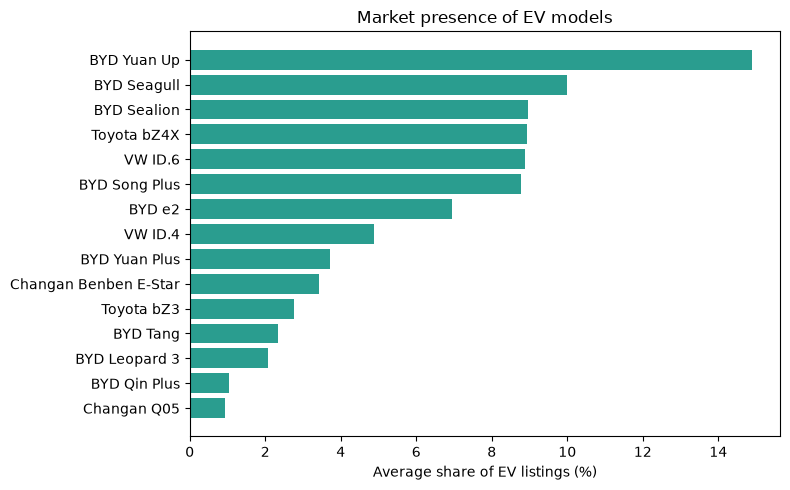

In [10]:
top = vehicles.head(15).sort_values("presence_share")
plt.figure(figsize=(8, 5))
plt.barh(top.index, top["presence_share"] * 100, color="#2a9d8f")
plt.xlabel("Average share of EV listings (%)")
plt.title("Market presence of EV models")
plt.tight_layout()
plt.show()

## 5. Vehicle selection

**Gates:** listed on at least 3 of 5 marketplaces and at least 100 listings. The final choice comes from the
assignment's candidates (ID.4 or ID.6 count as one).

| Criterion | Measure | Weight |
|---|---|---|
| C1 Market presence | `presence_share`, scaled 0–1 | 40% |
| C2 Fleet maturity | `share_2023_or_older`, scaled 0–1 | 25% |
| C3 After-sales gap | 0 official parts dealer, 0.5 unconfirmed, 1 grey imports only | 25% |
| C4 Low market risk | 0 if the model had an import ban, else 1 | 10% |

C1–C2 come from the data; C3–C4 are judgement based on distributor news:
BYD has an official dealer with genuine parts ([Addis Standard](https://addisstandard.com/chinese-ev-giant-byd-debuts-in-ethiopia-with-five-electric-models-moenco-partnership));
VW ID cars are grey imports and were banned, then allowed again ([Addis Fortune](https://addisfortune.news/fed-lifts-chinese-assembled-volkswagen-embargo));
Toyota and Changan official EV parts channels could not be confirmed.

In [11]:
CANDIDATES = ["BYD Seagull", "BYD Yuan Up", "Changan Benben E-Star", "Toyota bZ4X", "VW ID.4", "VW ID.6"]
AFTER_SALES_GAP = {"BYD": 0.0, "Toyota": 0.5, "Changan": 0.5, "VW": 1.0}
IMPORT_BAN_HISTORY = {"VW": 1}


def min_max(series):
    return (series - series.min()) / (series.max() - series.min())


def score(table, weights):
    total = 0
    for column, weight in weights.items():
        total = total + table[column] * weight
    return total


passes_gates = (vehicles["sources_present"] >= 3) & (vehicles["listings_total"] >= 100)
ranked = vehicles[passes_gates].copy()
brand = ranked.index.str.split().str[0]

ranked["c1_presence"] = min_max(ranked["presence_share"])
ranked["c2_maturity"] = min_max(ranked["share_2023_or_older"])
ranked["c3_gap"] = brand.map(AFTER_SALES_GAP).fillna(0.5).values
ranked["c4_low_risk"] = 1 - brand.map(IMPORT_BAN_HISTORY).fillna(0).values

WEIGHTS = {"c1_presence": 0.40, "c2_maturity": 0.25, "c3_gap": 0.25, "c4_low_risk": 0.10}
ranked["score"] = score(ranked, WEIGHTS)
ranked["candidate"] = ranked.index.isin(CANDIDATES)
ranked = ranked.sort_values("score", ascending=False)

ranked[["candidate", "c1_presence", "c2_maturity", "c3_gap", "c4_low_risk", "score"]].round(2)

,candidate,c1_presence,c2_maturity,c3_gap,c4_low_risk,score
model,,,,,,
VW ID.6,True,0.57,0.81,1.0,0.0,0.68
Toyota bZ4X,True,0.58,0.82,0.5,1.0,0.66
VW ID.4,True,0.29,1.00,1.0,0.0,0.61
BYD Yuan Up,True,1.00,0.01,0.0,1.0,0.50
Changan Benben E-Star,True,0.18,0.73,0.5,1.0,0.48
BYD Seagull,True,0.65,0.08,0.0,1.0,0.38
Toyota bZ3,False,0.13,0.22,0.5,1.0,0.33
BYD Sealion,False,0.58,0.00,0.0,1.0,0.33
BYD Song Plus,False,0.56,0.01,0.0,1.0,0.33


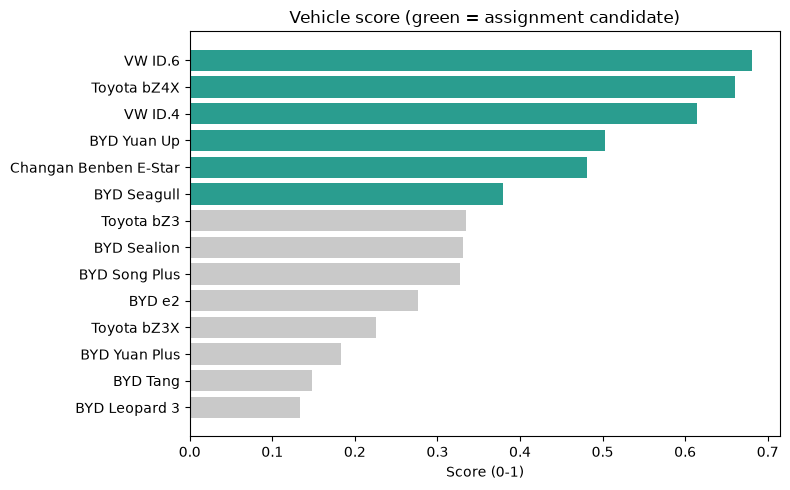

In [12]:
colors = ["#2a9d8f" if is_candidate else "#c9c9c9" for is_candidate in ranked["candidate"]]
plt.figure(figsize=(8, 5))
plt.barh(ranked.index[::-1], ranked["score"][::-1], color=colors[::-1])
plt.xlabel("Score (0-1)")
plt.title("Vehicle score (green = assignment candidate)")
plt.tight_layout()
plt.show()

### 5.1 Sensitivity

Do other weights change the three selected vehicles?

In [13]:
WEIGHT_SETS = {
    "base": WEIGHTS,
    "equal": {"c1_presence": 0.25, "c2_maturity": 0.25, "c3_gap": 0.25, "c4_low_risk": 0.25},
    "presence-heavy": {"c1_presence": 0.60, "c2_maturity": 0.20, "c3_gap": 0.10, "c4_low_risk": 0.10},
    "maturity-heavy": {"c1_presence": 0.30, "c2_maturity": 0.45, "c3_gap": 0.15, "c4_low_risk": 0.10},
    "gap-heavy": {"c1_presence": 0.30, "c2_maturity": 0.20, "c3_gap": 0.40, "c4_low_risk": 0.10},
    "data only": {"c1_presence": 0.60, "c2_maturity": 0.40, "c3_gap": 0.0, "c4_low_risk": 0.0},
}


def pick_three(scores):
    chosen = []
    for model in scores.sort_values(ascending=False).index:
        if model not in CANDIDATES:
            continue
        if model.startswith("VW") and any(m.startswith("VW") for m in chosen):
            continue
        chosen.append(model)
        if len(chosen) == 3:
            break
    return chosen


rows = []
for name, weights in WEIGHT_SETS.items():
    rows.append({"weights": name, "selected": ", ".join(pick_three(score(ranked, weights)))})
pd.DataFrame(rows)

,weights,selected
0,base,"VW ID.6, Toyota bZ4X, BYD Yuan Up"
1,equal,"Toyota bZ4X, Changan Benben E-Star, VW ID.6"
2,presence-heavy,"BYD Yuan Up, Toyota bZ4X, VW ID.6"
3,maturity-heavy,"Toyota bZ4X, VW ID.6, Changan Benben E-Star"
4,gap-heavy,"VW ID.6, Toyota bZ4X, Changan Benben E-Star"
5,data only,"Toyota bZ4X, VW ID.6, BYD Yuan Up"


### 5.2 Decision

**Selected: VW ID.6, Toyota bZ4X, BYD Yuan Up.**

* **VW ID.6** and **Toyota bZ4X** win under every weight set: high presence (about 9% each) and the oldest fleets (about 3 in 4 cars from 2023 or earlier).
* **Third place** is split between BYD Yuan Up (3 weight sets) and Changan Benben E-Star (3 weight sets).
  **Yuan Up** is chosen: it has by far the highest presence (14.9% vs 3.4%) and a BYD parts catalogue exists.
  The Benben E-Star is the reserve choice.
* **ID.6 over ID.4:** almost twice the presence (8.9% vs 4.9%).


In [14]:
ranked.to_csv(f"{OUTPUT_DIR}/vehicle_scores.csv")

### 5.3 Limitations

* No sales or registration data by model exists; presence on marketplaces is a proxy.
* Adey covers about the last 30 days of posts, so shares reflect recent activity.
* The same car can appear on several marketplaces; shares reduce but do not remove this.
* Gezat has only 10 distinct cars, some with implausible years; it counts only toward `sources_present`.
* C3 and C4 rely on news reports, not a parts-price survey.

## 6. Parts analysis

Next: parts evidence for the three selected vehicles.